# Depresión: FAISS, algoritmo genético y modelos supervisados

Notebook para **Google Colab, CPU**, en español. Ejecuta **Entorno de ejecución → Ejecutar todas**. El CSV adjunto está integrado, sin credenciales de Kaggle. Puedes indicar otro archivo en `DATA_PATH`.

**Pregunta:** ¿una ponderación de variables optimizada por un algoritmo genético mejora el clustering de dos grupos y su coincidencia con `depressed`? Se compara FAISS sin ponderar, FAISS + GA optimizando Silhouette, FAISS + GA optimizando Rand, regresión logística y una red neuronal pequeña. Se agrega un predictor de clase mayoritaria como referencia.

**Dependencias:** NumPy, Matplotlib, FAISS y PyTorch; biblioteca estándar para datos, tablas y archivos. No se necesita pandas ni scikit-learn. Regresión logística, partición y métricas se implementan con NumPy.

**Protocolo:** partición estratificada fija 60/20/20, imputación y escalado ajustados solo en entrenamiento, selección en validación y evaluación final en prueba. Se repiten tres semillas de los algoritmos sobre la misma partición. Esto mide variabilidad del algoritmo, no incertidumbre de otras muestras ni generalización a otros municipios.


In [1]:
# FAISS se instala únicamente si falta. Colab ya incluye las otras dependencias.
import importlib.util, subprocess, sys
if importlib.util.find_spec("faiss") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "faiss-cpu>=1.8,<2"])
if importlib.util.find_spec("torch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch>=2,<3"])
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import faiss
import random, csv, io, time, copy, json, base64, zlib, hashlib, platform
from pathlib import Path
from IPython.display import display, Markdown, HTML
faiss.omp_set_num_threads(1)
torch.set_num_threads(1)
SEED_SPLIT = 2026
SEEDS = [17, 42, 91]
GA_POP, GA_GENERATIONS = 20, 25  # Aumentar para una búsqueda más extensa.
GA_KEEP, GA_MUTATION, GA_SIGMA = 0.35, 0.15, 0.15
K = 2
DATA_PATH = None  # Ejemplo: "/content/b_depressed.csv"; None usa la copia integrada.
OUTPUT_DIR = Path("resultados_depresion")
OUTPUT_DIR.mkdir(exist_ok=True)
print({"Python": platform.python_version(), "NumPy": np.__version__,
       "FAISS": getattr(faiss, "__version__", "desconocida"), "PyTorch": torch.__version__})
print("CPU, semillas:", SEEDS, "| GA:", GA_POP, "individuos x", GA_GENERATIONS, "generaciones")


{'Python': '3.12.14', 'NumPy': '2.5.4', 'FAISS': '1.15.1', 'PyTorch': '2.14.1+cpu'}
CPU, semillas: [17, 42, 91] | GA: 20 individuos x 25 generaciones


## 1. Datos y auditoría

Fuente indicada: [Depression — Diego Babativa, Kaggle](https://www.kaggle.com/datasets/diegobabativa/depression). El análisis utiliza exactamente `b_depressed.csv` adjunto: 1,429 filas y 23 columnas. `depressed` es la etiqueta binaria proporcionada por el dataset. Se excluyen `Survey_id` y `Ville_id`: son identificadores, y el municipio numérico no es una magnitud continua.

Se verifica la copia integrada con SHA-256. No se modifica el archivo original. Los faltantes se imputan con la mediana de entrenamiento; se agregan indicadores de ausencia en las columnas que tienen faltantes en entrenamiento. Las variables numéricas se estandarizan con media y desviación de entrenamiento. No se asumen unidades monetarias ni se aplican transformaciones logarítmicas sin documentación.


SHA-256: 84ab2f5d77d5c9bcdca5d37b894d28517211b22b8995da07a06f4b4714c074d7
Filas: 1429 | Columnas originales: 23
Clases 0/1: [1191  238] | Prevalencia: 0.1666
Valores faltantes: {'no_lasting_investmen': 20}


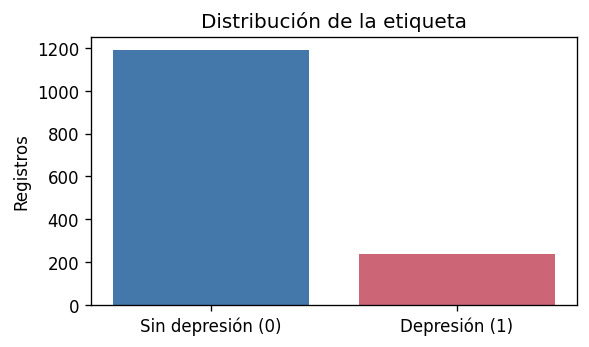

In [2]:
CSV_B64_ZLIB = '...'
CSV_SHA256 = '84ab2f5d77d5c9bcdca5d37b894d28517211b22b8995da07a06f4b4714c074d7'
if DATA_PATH is None:
    csv_bytes = zlib.decompress(base64.b64decode(CSV_B64_ZLIB))
    assert hashlib.sha256(csv_bytes).hexdigest() == CSV_SHA256
else:
    csv_bytes = Path(DATA_PATH).read_bytes()
print("SHA-256:", hashlib.sha256(csv_bytes).hexdigest())
rows = list(csv.DictReader(io.StringIO(csv_bytes.decode("utf-8-sig"))))
assert rows and "depressed" in rows[0]
all_names = list(rows[0])
def number(v):
    return float(v) if v.strip().lower() not in ("", "na", "nan", "null", "none") else np.nan
A = np.array([[number(row[c]) for c in all_names] for row in rows], dtype=np.float64)
y_raw = A[:, all_names.index("depressed")]
assert np.isfinite(y_raw).all() and set(np.unique(y_raw)) == {0., 1.}, "Etiqueta inválida"
y = y_raw.astype(np.int64)
feature_names_raw = [n for n in all_names if n not in ("depressed", "Survey_id", "Ville_id")]
X_raw = A[:, [all_names.index(n) for n in feature_names_raw]]
X_raw[~np.isfinite(X_raw)] = np.nan
assert len(X_raw) == len(y)
print("Filas:", len(y), "| Columnas originales:", len(all_names))
print("Clases 0/1:", np.bincount(y), "| Prevalencia:", round(y.mean(), 4))
print("Valores faltantes:", {n:int(np.isnan(X_raw[:,j]).sum()) for j,n in enumerate(feature_names_raw) if np.isnan(X_raw[:,j]).any()})
if "Survey_id" in all_names:
    assert len(np.unique(A[:,all_names.index("Survey_id")])) == len(y), "IDs repetidos: revisar partición por persona"
fig, ax = plt.subplots(figsize=(5,3))
ax.bar(["Sin depresión (0)", "Depresión (1)"], np.bincount(y), color=["#4477aa", "#cc6677"])
ax.set_ylabel("Registros"); ax.set_title("Distribución de la etiqueta")
plt.tight_layout(); plt.show()


In [3]:
def stratified_split(y, seed=SEED_SPLIT):
    rng = np.random.default_rng(seed)
    train, val, test = [], [], []
    for label in np.unique(y):
        ids = rng.permutation(np.flatnonzero(y == label))
        n1, n2 = int(0.60*len(ids)), int(0.20*len(ids))
        train.extend(ids[:n1]); val.extend(ids[n1:n1+n2]); test.extend(ids[n1+n2:])
    return tuple(rng.permutation(v) for v in (train, val, test))
idx_train, idx_val, idx_test = stratified_split(y)
assert not set(idx_train) & set(idx_val)
assert not set(idx_train) & set(idx_test)
assert not set(idx_val) & set(idx_test)
assert len(set(np.concatenate([idx_train,idx_val,idx_test]))) == len(y)

class Preprocessor:
    def fit(self, X, names):
        self.median = np.nanmedian(X, axis=0)
        if not np.isfinite(self.median).all():
            raise ValueError("Columna completamente ausente en entrenamiento")
        self.missing_cols = np.flatnonzero(np.isnan(X).any(axis=0))
        self.names = list(names) + [names[j]+"__faltante" for j in self.missing_cols]
        Z = self.impute(X)
        self.mean, self.std = Z.mean(axis=0), Z.std(axis=0)
        self.std = np.where(self.std < 1e-8, 1., self.std)
        return self
    def impute(self, X):
        Z = np.where(np.isnan(X), self.median, X)
        return np.column_stack([Z, np.isnan(X[:, self.missing_cols]).astype(float)])
    def transform(self, X):
        return np.ascontiguousarray((self.impute(X)-self.mean)/self.std, dtype=np.float32)
prep = Preprocessor().fit(X_raw[idx_train], feature_names_raw)
Xtr, Xva, Xte = [prep.transform(X_raw[idx]) for idx in (idx_train, idx_val, idx_test)]
ytr, yva, yte = [y[idx] for idx in (idx_train, idx_val, idx_test)]
feature_names = prep.names
for name, xx, yy in zip(["train", "validación", "prueba"], [Xtr,Xva,Xte], [ytr,yva,yte]):
    assert np.isfinite(xx).all()
    print(f"{name:12}: {len(yy)} filas, {xx.shape[1]} variables, clases {np.bincount(yy)}")


train       : 856 filas, 21 variables, clases [714 142]
validación  : 285 filas, 21 variables, clases [238  47]
prueba      : 288 filas, 21 variables, clases [239  49]


## 2. Métricas implementadas con NumPy

- **Silhouette**: promedio de $(b_i-a_i)/\max(a_i,b_i)$, con distancias euclidianas (no cuadradas). Un singleton recibe 0. Si hay menos de dos grupos, se devuelve `NaN`. Mayor es mejor; rango $[-1,1]$.
- **Rand Index (RI)**: proporción de pares que ambas particiones agrupan o separan igual. No depende del nombre 0/1 de cada cluster. Rango $[0,1]$.
- **Adjusted Rand Index (ARI)**: corrige el acuerdo esperado por azar; sirve para contextualizar RI con clases desbalanceadas.
- Para la comparación predictiva: accuracy, balanced accuracy, precisión, recall, F1 y ROC-AUC. El umbral de cada modelo supervisado se elige por balanced accuracy en validación. RI/ARI también se calculan para las predicciones de clase de los clasificadores.

Para FAISS se muestran dos Silhouettes: **espacio propio** (ponderado) y **espacio común** (estandarizado sin pesos). Solo el segundo compara geometría sobre la misma representación. En clasificadores, Silhouette describe la partición predicha; no es una función de entrenamiento ni una medida de calidad probabilística.


In [4]:
def euclidean_matrix(X):
    Z = np.asarray(X, dtype=np.float64)
    D2 = np.maximum((Z*Z).sum(1)[:,None] + (Z*Z).sum(1)[None,:] - 2*Z@Z.T, 0.)
    D = np.sqrt(D2)
    np.fill_diagonal(D, 0.)
    return D

def silhouette_numpy(X, labels, D=None):
    labels = np.asarray(labels)
    groups = np.unique(labels)
    n = len(labels)
    if not 2 <= len(groups) < n:
        return np.nan
    D = euclidean_matrix(X) if D is None else D
    scores = np.zeros(n)
    for g in groups:
        own = np.flatnonzero(labels == g)
        if len(own) == 1:
            continue
        a = D[np.ix_(own,own)].sum(axis=1)/(len(own)-1)
        b = np.min(np.column_stack([D[np.ix_(own,np.flatnonzero(labels==h))].mean(1)
                                   for h in groups if h != g]), axis=1)
        den = np.maximum(a,b)
        scores[own] = np.divide(b-a, den, out=np.zeros_like(a), where=den>0)
    return float(scores.mean())

def rand_scores(y_true, labels):
    _, a = np.unique(y_true, return_inverse=True)
    _, b = np.unique(labels, return_inverse=True)
    n = len(a)
    if n < 2: return np.nan, np.nan
    table = np.zeros((a.max()+1,b.max()+1), dtype=np.int64)
    np.add.at(table,(a,b),1)
    c2 = lambda z: np.sum(z*(z-1)/2)
    tp, same_a, same_b, total = c2(table), c2(table.sum(1)), c2(table.sum(0)), n*(n-1)/2
    ri = (total-same_a-same_b+2*tp)/total
    expected = same_a*same_b/total
    denominator = (same_a+same_b)/2-expected
    ari = (tp-expected)/denominator if abs(denominator)>1e-12 else 1.
    return float(ri), float(ari)

def auc_numpy(y, p):
    # Mann–Whitney con rango promedio para empates.
    order = np.argsort(p, kind="mergesort")
    sorted_p = np.asarray(p)[order]
    ranks = np.empty(len(p), dtype=float)
    start = 0
    while start < len(p):
        end = start+1
        while end<len(p) and sorted_p[end]==sorted_p[start]: end+=1
        ranks[order[start:end]] = (start+1+end)/2
        start = end
    n1, n0 = int(np.sum(y==1)), int(np.sum(y==0))
    if n1*n0 == 0: return np.nan
    return float((ranks[np.asarray(y)==1].sum()-n1*(n1+1)/2)/(n1*n0))

def classification_metrics(y, pred, score):
    tp = int(np.sum((y==1)&(pred==1))); tn = int(np.sum((y==0)&(pred==0)))
    fp = int(np.sum((y==0)&(pred==1))); fn = int(np.sum((y==1)&(pred==0)))
    precision = tp/max(tp+fp,1); recall=tp/max(tp+fn,1)
    specificity = tn/max(tn+fp,1)
    return dict(accuracy=(tp+tn)/len(y), balanced_accuracy=(recall+specificity)/2,
                precision=precision, recall=recall, f1=2*tp/max(2*tp+fp+fn,1),
                roc_auc=auc_numpy(y,score), tn=tn, fp=fp, fn=fn, tp=tp)

def best_threshold(y, p):
    # Incluye todas las particiones posibles y resuelve empates cerca de 0.5.
    vals = np.unique(p)
    thresholds = np.r_[0., (vals[:-1]+vals[1:])/2, 0.5, np.nextafter(1.,2.)]
    scores = np.array([classification_metrics(y,(p>=t).astype(int),p)["balanced_accuracy"] for t in thresholds])
    candidates = np.flatnonzero(np.isclose(scores,scores.max(),atol=1e-12,rtol=0))
    best = candidates[np.argmin(abs(thresholds[candidates]-.5))]
    return float(thresholds[best]), float(scores[best])

# Comprobaciones de propiedades y casos límite.
assert rand_scores([0,0,1,1],[1,1,0,0]) == (1.,1.)
assert np.isclose(auc_numpy(np.array([0,1]),np.array([.5,.5])), .5)
assert np.isclose(auc_numpy(np.array([0,1]),np.array([.1,.9])), 1.)
assert np.isnan(silhouette_numpy(np.zeros((3,2)), np.zeros(3)))
assert np.isfinite(silhouette_numpy(np.array([[0.],[1.],[10.]]), [0,0,1]))
print("Comprobaciones básicas de métricas: OK")


Comprobaciones básicas de métricas: OK


## 3. FAISS k-means y pesos reales

FAISS aprende **dos centroides sobre entrenamiento** y asigna los puntos de validación/prueba al centro más próximo. No se usa `depressed` como variable.

Un cromosoma contiene un peso por variable: $w_j\in[-1,1]$. Se transforma $z_j=w_j x_j$ y se aplica k-means. La distancia es

$$d_w^2(x,x')=\sum_j w_j^2(x_j-x'_j)^2.$$

Por eso, el signo del peso no indica una relación positiva o negativa con depresión. Se reporta $w_j^2/\sum_k w_k^2$ como contribución relativa a la métrica. La escala global no cambia la geometría relativa; normalizamos cada cromosoma por su máximo absoluto. Esto conserva el intervalo y evita explorar copias que solo cambian de escala. El vector cero se rechaza.

Para obtener predicciones clínicas binarias de los clusters, se comparan las dos correspondencias posibles cluster→clase **solo con etiquetas de entrenamiento**, eligiendo balanced accuracy. El score de cada cluster es su frecuencia de positivos en entrenamiento, suavizada. RI y ARI no necesitan esta correspondencia.


In [5]:
def weight_data(X, w):
    return np.ascontiguousarray(X*np.asarray(w,dtype=np.float32), dtype=np.float32)

def fit_faiss(X, w, seed):
    Z = weight_data(X,w)
    model = faiss.Kmeans(Z.shape[1], K, niter=30, nredo=3, seed=int(seed),
                         verbose=False, gpu=False, min_points_per_centroid=1,
                         max_points_per_centroid=len(X))
    model.train(Z)
    return model

def assign(model, X, w):
    return model.index.search(weight_data(X,w),1)[1].ravel().astype(int)

def cluster_calibration(train_clusters, y):
    identity = train_clusters.copy()
    a = classification_metrics(y,identity,identity)["balanced_accuracy"]
    b = classification_metrics(y,1-identity,1-identity)["balanced_accuracy"]
    mapping = np.array([0,1]) if a>=b else np.array([1,0])
    prevalence = y.mean()
    probs = np.array([(y[train_clusters==k].sum()+2*prevalence)/
                      (np.sum(train_clusters==k)+2) for k in range(K)])
    return mapping, probs


## 4. Algoritmo genético basado en `genetic.py`

Se conserva la estructura del código adjunto: **generar población → evaluar costo → ordenar → seleccionar → cruzar → mutar → repetir**. Las diferencias son:

1. Los genes son reales, sin representación binaria ni decodificación.
2. Se ordenan juntos individuos y costos; así los padres seleccionados siempre corresponden a sus evaluaciones. En el original se ordenaban costos e individuos por caminos distintos.
3. La población mantiene tamaño fijo, y los dos mejores individuos sobreviven sin mutación.
4. Cruce aritmético, mutación gaussiana y recorte a `[-1,1]`. Se usa selección de padres ponderada por rango, estable ante empates.
5. Se evalúa cada población, incluida la última, y se retorna el mejor individuo **evaluado**.

Se ejecutan **dos búsquedas separadas**, minimizando `costo = -métrica_validación`:

- `GA-Silhouette`: optimiza Silhouette en el espacio ponderado; no utiliza etiquetas en su fitness. La partición estratificada y la posterior correspondencia de clases sí usan etiquetas, por lo que solo la búsqueda geométrica es no supervisada.
- `GA-Rand`: optimiza RI contra `depressed` en validación. Es selección de una métrica con supervisión; no debe presentarse como clustering completamente no supervisado.

El individuo de pesos iguales está incluido en cada población inicial. Se rechazan soluciones con menos de dos clusters representados o clusters de menos de dos puntos en entrenamiento/validación. No se obliga a reproducir el tamaño de las clases. El algoritmo busca una buena solución dentro del presupuesto; no garantiza el óptimo global. Reutilizar validación muchas veces puede sobreajustarla: la prueba permanece fuera de todas las decisiones.


In [6]:
def normalize_population(pop):
    pop = np.clip(np.asarray(pop,dtype=np.float64),-1.,1.)
    scale = np.max(np.abs(pop),axis=1,keepdims=True)
    return pop/np.maximum(scale,1e-12)

def generate_real_pop(size, npar, rng):
    pop = normalize_population(rng.uniform(-1.,1.,size=(size,npar)))
    pop[0] = 1.  # Referencia sin ponderación.
    return pop

def rank(evaluation, population):
    order = np.argsort(evaluation,kind="stable")
    return population[order].copy(), np.asarray(evaluation)[order]

def selection(population, keep):
    return population[:max(2,int(np.ceil(len(population)*keep)))].copy()

def random_cross(ma, pa, rng):
    alpha = rng.uniform(0.,1.,size=ma.shape)
    return alpha*ma+(1-alpha)*pa

def uranium_exposure(population, mutrate, sigma, rng):
    mask = rng.random(population.shape)<mutrate
    noise = rng.normal(0.,sigma,size=population.shape)
    return normalize_population(population+mask*noise)

def make_objective(Xtrain, Xvalid, yvalid, objective, seed):
    cache = {}
    def cost(w):
        key = np.asarray(w,dtype=np.float64).tobytes()
        if key in cache: return cache[key]
        if np.max(np.abs(w))<1e-8:
            return 2.
        model = fit_faiss(Xtrain,w,seed)
        ct, cv = assign(model,Xtrain,w), assign(model,Xvalid,w)
        if min(np.bincount(ct,minlength=K))<2 or min(np.bincount(cv,minlength=K))<2:
            value = 2.  # Peor que cualquier costo válido.
        else:
            metric = (silhouette_numpy(weight_data(Xvalid,w),cv) if objective=="silhouette"
                      else rand_scores(yvalid,cv)[0])
            value = -metric if np.isfinite(metric) else 2.
        cache[key]=float(value)
        return float(value)
    return cost

def the_ga(f, popsize, npar, generations, keep, mutrate, sigma, seed):
    assert popsize>=4 and generations>=1 and 0<keep<1
    rng = np.random.default_rng(seed)
    pop = generate_real_pop(popsize,npar,rng)
    history = []
    for generation in range(generations+1):
        costs = np.array([f(w) for w in pop])
        pop, costs = rank(costs,pop)
        valid = costs<2.
        history.append([generation, costs[0], costs[valid].mean() if valid.any() else np.nan])
        if generation == generations: break
        parents = selection(pop,keep)
        probs = np.arange(len(parents),0,-1,dtype=float)
        probs /= probs.sum()
        nchild=popsize-2
        ma=parents[rng.choice(len(parents),nchild,p=probs)]
        pa=parents[rng.choice(len(parents),nchild,p=probs)]
        children=uranium_exposure(random_cross(ma,pa,rng),mutrate,sigma,rng)
        pop=np.vstack([pop[:2],children])
        assert pop.shape==(popsize,npar) and np.max(abs(pop))<=1.+1e-12
    assert costs[0]<2., "Ninguna solución válida; revisar datos o aumentar búsqueda"
    return pop[0].copy(), float(costs[0]), np.asarray(history)

# Prueba del GA en una función real con óptimo conocido dentro del intervalo.
probe_w, probe_cost, probe_hist = the_ga(lambda w: float(np.sum((w-.25)**2)),
                                        16,3,15,.4,.3,.15,7)
assert probe_cost<=probe_hist[0,1]+1e-12
assert np.all(np.diff(probe_hist[:,1])<=1e-12)
assert np.max(abs(probe_w))<=1.
print("GA real: elitismo, límites y mejor costo evaluado verificados")


GA real: elitismo, límites y mejor costo evaluado verificados


## 5. Regresión logística (NumPy) y red neuronal (PyTorch)

La regresión logística minimiza entropía cruzada binaria con L2 usando gradientes y Adam implementados con NumPy. Se prueban tres regularizaciones (`1e-4`, `1e-2`, `1e-1`), con 1,200 pasos por opción. Se conserva el checkpoint de menor pérdida de validación y se elige configuración/umbral por balanced accuracy de validación.

La red ligera tiene capas `d → 16 → 8 → 1`, ReLU y dropout 0.10. Usa `BCEWithLogitsLoss`, Adam, lotes de 64, máximo 250 épocas y parada temprana de 30 épocas. Se conserva el checkpoint de menor pérdida de validación. Ambos modelos se entrenan con la distribución original, y compensan la decisión de clase mediante el umbral elegido en validación. No se remuestrea ni se pondera la pérdida.

La comparación es entre familias con distinta información: FAISS base y GA-Silhouette no usan etiquetas para entrenar la geometría; GA-Rand usa etiquetas de validación; logística y MLP usan etiquetas de entrenamiento. Los presupuestos de optimización también difieren y se reporta tiempo.


In [7]:
def sigmoid(z):
    z=np.clip(z,-60,60)
    return 1./(1.+np.exp(-z))

def bce_logits(y, z):
    return float(np.mean(np.logaddexp(0,z)-y*z))

def fit_logistic(X,y,Xval,yval,l2,steps=1200,lr=.03):
    Z=np.column_stack([X,np.ones(len(X))]).astype(np.float64)
    V=np.column_stack([Xval,np.ones(len(Xval))]).astype(np.float64)
    beta=np.zeros(Z.shape[1]); m=np.zeros_like(beta); v=np.zeros_like(beta)
    best_loss=np.inf; best=beta.copy()
    for t in range(1,steps+1):
        grad=Z.T@(sigmoid(Z@beta)-y)/len(y)
        grad[:-1]+=l2*beta[:-1]
        m=.9*m+.1*grad; v=.999*v+.001*grad**2
        beta-=lr*(m/(1-.9**t))/(np.sqrt(v/(1-.999**t))+1e-8)
        if t%10==0:
            loss=bce_logits(yval,V@beta)
            if loss<best_loss: best_loss=loss; best=beta.copy()
    return best

def predict_logistic(X,beta):
    return sigmoid(np.column_stack([X,np.ones(len(X))])@beta)

def select_logistic(X,y,Xval,yval):
    candidates=[]
    for l2 in [1e-4,1e-2,1e-1]:
        beta=fit_logistic(X,y,Xval,yval,l2)
        p=predict_logistic(Xval,beta)
        threshold,score=best_threshold(yval,p)
        candidates.append(dict(beta=beta,l2=l2,threshold=threshold,val_ba=score,
                               val_loss=bce_logits(yval,np.column_stack([Xval,np.ones(len(Xval))])@beta)))
    return max(candidates,key=lambda c:(c["val_ba"],-c["val_loss"]))

def fit_mlp(X,y,Xval,yval,seed):
    torch.manual_seed(seed); random.seed(seed)
    net=nn.Sequential(nn.Linear(X.shape[1],16),nn.ReLU(),nn.Dropout(.1),
                      nn.Linear(16,8),nn.ReLU(),nn.Linear(8,1))
    optimizer=torch.optim.Adam(net.parameters(),lr=.003,weight_decay=.001)
    criterion=nn.BCEWithLogitsLoss()
    xt=torch.tensor(X,dtype=torch.float32); yt=torch.tensor(y,dtype=torch.float32)
    xv=torch.tensor(Xval,dtype=torch.float32); yv=torch.tensor(yval,dtype=torch.float32)
    best_loss=np.inf; best=None; patience=0; history=[]; best_epoch=0
    for epoch in range(250):
        net.train()
        for ids in torch.randperm(len(y)).split(64):
            optimizer.zero_grad()
            loss=criterion(net(xt[ids]).ravel(),yt[ids])
            loss.backward(); optimizer.step()
        net.eval()
        with torch.no_grad():
            train_loss=criterion(net(xt).ravel(),yt).item()
            val_loss=criterion(net(xv).ravel(),yv).item()
        history.append([train_loss,val_loss])
        if val_loss<best_loss-1e-5:
            best_loss=val_loss; best=copy.deepcopy(net.state_dict()); patience=0; best_epoch=epoch+1
        else: patience+=1
        if patience>=30: break
    net.load_state_dict(best); net.eval()
    return net,np.asarray(history),best_epoch

def predict_mlp(net,X):
    net.eval()
    with torch.no_grad():
        return torch.sigmoid(net(torch.tensor(X,dtype=torch.float32)).ravel()).numpy()


## 6. Entrenar y seleccionar sin consultar prueba

Las búsquedas de pesos utilizan exactamente el mismo entrenamiento/validación. Cada evaluación de fitness vuelve a entrenar FAISS con la misma semilla dentro de esa ejecución para evitar ruido entre candidatos. El fitness se calcula con todos los puntos de validación. La muestra es pequeña, así que Silhouette se calcula exactamente.

Se mantienen los centroides ajustados en entrenamiento: no se reentrena con validación antes de prueba. La regresión logística es determinista y se calcula una sola vez; sus tres filas de resultados coincidirán y su desviación será cero.


In [8]:
artifacts=[]; training_log=[]; ga_histories={}; mlp_histories={}
t0=time.perf_counter()
logistic=select_logistic(Xtr,ytr,Xva,yva)
logistic_seconds=time.perf_counter()-t0
print("Logística: L2 =",logistic["l2"],"umbral =",round(logistic["threshold"],4),
      "BA validación =",round(logistic["val_ba"],4))
for seed in SEEDS:
    print("Semilla",seed,flush=True)
    for method, objective in [("FAISS base",None),("FAISS + GA Silhouette","silhouette"),
                              ("FAISS + GA Rand","rand")]:
        start=time.perf_counter()
        if objective is None:
            weights=np.ones(Xtr.shape[1]); history=None; best_cost=np.nan
        else:
            objective_fn=make_objective(Xtr,Xva,yva,objective,seed)
            weights,best_cost,history=the_ga(objective_fn,GA_POP,Xtr.shape[1],GA_GENERATIONS,
                                            GA_KEEP,GA_MUTATION,GA_SIGMA,seed)
            ga_histories[(method,seed)]=history
        model=fit_faiss(Xtr,weights,seed)
        train_c=assign(model,Xtr,weights)
        mapping,probs=cluster_calibration(train_c,ytr)
        valid_c=assign(model,Xva,weights)
        val_ri,val_ari=rand_scores(yva,valid_c)
        val_sil=silhouette_numpy(weight_data(Xva,weights),valid_c)
        artifacts.append(dict(method=method,seed=seed,kind="cluster",weights=weights,
                              model=model,mapping=mapping,probs=probs))
        training_log.append(dict(method=method,seed=seed,seconds=time.perf_counter()-start,
                                 val_ri=val_ri,val_silhouette=val_sil,
                                 val_ba=classification_metrics(yva,mapping[valid_c],probs[valid_c])["balanced_accuracy"]))
        print(" ",method,"| RI val:",round(val_ri,4),"| Sil val:",round(val_sil,4),flush=True)
    start=time.perf_counter()
    net,history,best_epoch=fit_mlp(Xtr,ytr,Xva,yva,seed)
    pval=predict_mlp(net,Xva)
    threshold,score=best_threshold(yva,pval)
    mlp_histories[seed]=history
    artifacts.append(dict(method="Red neuronal ligera",seed=seed,kind="mlp",model=net,threshold=threshold))
    training_log.append(dict(method="Red neuronal ligera",seed=seed,seconds=time.perf_counter()-start,
                             val_ba=score,best_epoch=best_epoch,threshold=threshold))
    artifacts.append(dict(method="Regresión logística",seed=seed,kind="logistic",**logistic))
    training_log.append(dict(method="Regresión logística",seed=seed,seconds=logistic_seconds,
                             val_ba=logistic["val_ba"],threshold=logistic["threshold"]))
    artifacts.append(dict(method="Clase mayoritaria",seed=seed,kind="majority"))
    training_log.append(dict(method="Clase mayoritaria",seed=seed,seconds=0.))
print("Entrenamiento y selección terminados. Ahora se evalúa prueba.")


Logística: L2 = 0.1 umbral = 0.1554 BA validación = 0.5717
Semilla 17
  FAISS base | RI val: 0.5887 | Sil val: 0.202
  FAISS + GA Silhouette | RI val: 0.6108 | Sil val: 0.8786
  FAISS + GA Rand | RI val: 0.6664 | Sil val: 0.3417
Semilla 42
  FAISS base | RI val: 0.5368 | Sil val: 0.1775
  FAISS + GA Silhouette | RI val: 0.6664 | Sil val: 0.8085
  FAISS + GA Rand | RI val: 0.6664 | Sil val: 0.3127
Semilla 91
  FAISS base | RI val: 0.601 | Sil val: 0.1598
  FAISS + GA Silhouette | RI val: 0.6354 | Sil val: 0.8117
  FAISS + GA Rand | RI val: 0.6664 | Sil val: 0.3668
Entrenamiento y selección terminados. Ahora se evalúa prueba.


## 7. Evaluación final sobre prueba reservada

Todas las métricas que siguen se calculan sobre las mismas filas de prueba. Los modelos ya están elegidos. La columna `Silhouette común` usa `Xte` para todos. `Silhouette propio` aplica los pesos de cada clustering; es `NaN` en clasificadores y en la referencia mayoritaria porque no tienen una geometría aprendida de clustering.

Las métricas de clasificación de FAISS usan la correspondencia fijada en entrenamiento. Si un clasificador produce una sola clase, su Silhouette común es `NaN`. Los scores probabilísticos de FAISS solo tienen dos valores, por lo que su ROC-AUC tiene menor resolución que el de los clasificadores.


In [9]:
Dtest=euclidean_matrix(Xte)
results=[]; predictions={}
for art in artifacts:
    kind=art["kind"]
    if kind=="cluster":
        clusters=assign(art["model"],Xte,art["weights"])
        pred=art["mapping"][clusters]; score=art["probs"][clusters]
        partition=clusters
        sil_own=silhouette_numpy(weight_data(Xte,art["weights"]),partition)
    elif kind=="logistic":
        score=predict_logistic(Xte,art["beta"])
        pred=(score>=art["threshold"]).astype(int); partition=pred; sil_own=np.nan
    elif kind=="mlp":
        score=predict_mlp(art["model"],Xte)
        pred=(score>=art["threshold"]).astype(int); partition=pred; sil_own=np.nan
    else:
        score=np.full(len(yte),ytr.mean())
        pred=np.full(len(yte),np.argmax(np.bincount(ytr)),dtype=int)
        partition=pred; sil_own=np.nan
    ri,ari=rand_scores(yte,partition)
    timing=next(r["seconds"] for r in training_log if r["method"]==art["method"] and r["seed"]==art["seed"])
    row=dict(method=art["method"],seed=art["seed"],rand_index=ri,adjusted_rand=ari,
             silhouette_common=silhouette_numpy(Xte,partition,D=Dtest),
             silhouette_own=sil_own,seconds=timing,
             **classification_metrics(yte,pred,score))
    results.append(row)
    predictions[(art["method"],art["seed"])]=dict(pred=pred,score=score,partition=partition)

METHODS=["Clase mayoritaria","FAISS base","FAISS + GA Silhouette","FAISS + GA Rand",
         "Regresión logística","Red neuronal ligera"]
METRICS=["rand_index","adjusted_rand","silhouette_common","silhouette_own",
         "accuracy","balanced_accuracy","precision","recall","f1","roc_auc","seconds"]
LABELS=["Rand","Rand ajustado","Silhouette común","Silhouette propio","Accuracy",
        "Balanced accuracy","Precisión","Recall","F1","ROC-AUC","Segundos entrenamiento"]
summary={}
for method in METHODS:
    subset=[r for r in results if r["method"]==method]
    summary[method]={}
    for metric in METRICS:
        vals=np.array([r[metric] for r in subset],dtype=float)
        vals=vals[np.isfinite(vals)]
        summary[method][metric]=(float(vals.mean()),float(vals.std(ddof=1)) if len(vals)>1 else 0.) if len(vals) else (np.nan,np.nan)

def show_summary(metrics, labels):
    header="<tr><th>Método</th>"+"".join(f"<th>{v}</th>" for v in labels)+"</tr>"
    body=""
    for method in METHODS:
        body+=f"<tr><td>{method}</td>"
        for metric in metrics:
            mean,std=summary[method][metric]
            body+="<td>—</td>" if not np.isfinite(mean) else f"<td>{mean:.3f} ± {std:.3f}</td>"
        body+="</tr>"
    display(HTML("<table>"+header+body+"</table>"))
display(Markdown("**Resultados de prueba: media ± desviación estándar entre semillas.**"))
show_summary(METRICS[:4],LABELS[:4])
show_summary(METRICS[4:],LABELS[4:])
print("Prueba:",len(yte),"registros;",int(yte.sum()),"positivos. Desviación entre semillas, no intervalo de confianza.")


Prueba: 288 registros; 49 positivos. Desviación entre semillas, no intervalo de confianza.


**Resultados de prueba: media ± desviación estándar entre semillas.**

Método,Rand,Rand ajustado,Silhouette común,Silhouette propio
Clase mayoritaria,0.717 ± 0.000,0.000 ± 0.000,—,—
FAISS base,0.541 ± 0.040,-0.004 ± 0.049,0.157 ± 0.017,0.157 ± 0.017
FAISS + GA Silhouette,0.604 ± 0.045,-0.021 ± 0.027,0.165 ± 0.021,0.823 ± 0.030
FAISS + GA Rand,0.647 ± 0.009,0.004 ± 0.001,0.161 ± 0.005,0.320 ± 0.025
Regresión logística,0.499 ± 0.000,-0.003 ± 0.000,0.043 ± 0.000,—
Red neuronal ligera,0.524 ± 0.022,0.032 ± 0.025,0.045 ± 0.009,—


Método,Accuracy,Balanced accuracy,Precisión,Recall,F1,ROC-AUC,Segundos entrenamiento
Clase mayoritaria,0.830 ± 0.000,0.500 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.000 ± 0.000
FAISS base,0.597 ± 0.133,0.522 ± 0.063,0.182 ± 0.063,0.408 ± 0.294,0.240 ± 0.094,0.522 ± 0.063,0.005 ± 0.001
FAISS + GA Silhouette,0.385 ± 0.244,0.486 ± 0.032,0.148 ± 0.040,0.639 ± 0.448,0.229 ± 0.102,0.486 ± 0.032,1.242 ± 0.436
FAISS + GA Rand,0.228 ± 0.008,0.497 ± 0.000,0.169 ± 0.000,0.905 ± 0.012,0.285 ± 0.001,0.497 ± 0.000,0.870 ± 0.321
Regresión logística,0.524 ± 0.000,0.592 ± 0.000,0.218 ± 0.000,0.694 ± 0.000,0.332 ± 0.000,0.623 ± 0.000,0.336 ± 0.000
Red neuronal ligera,0.605 ± 0.052,0.586 ± 0.011,0.231 ± 0.017,0.558 ± 0.066,0.325 ± 0.010,0.591 ± 0.008,1.026 ± 0.741


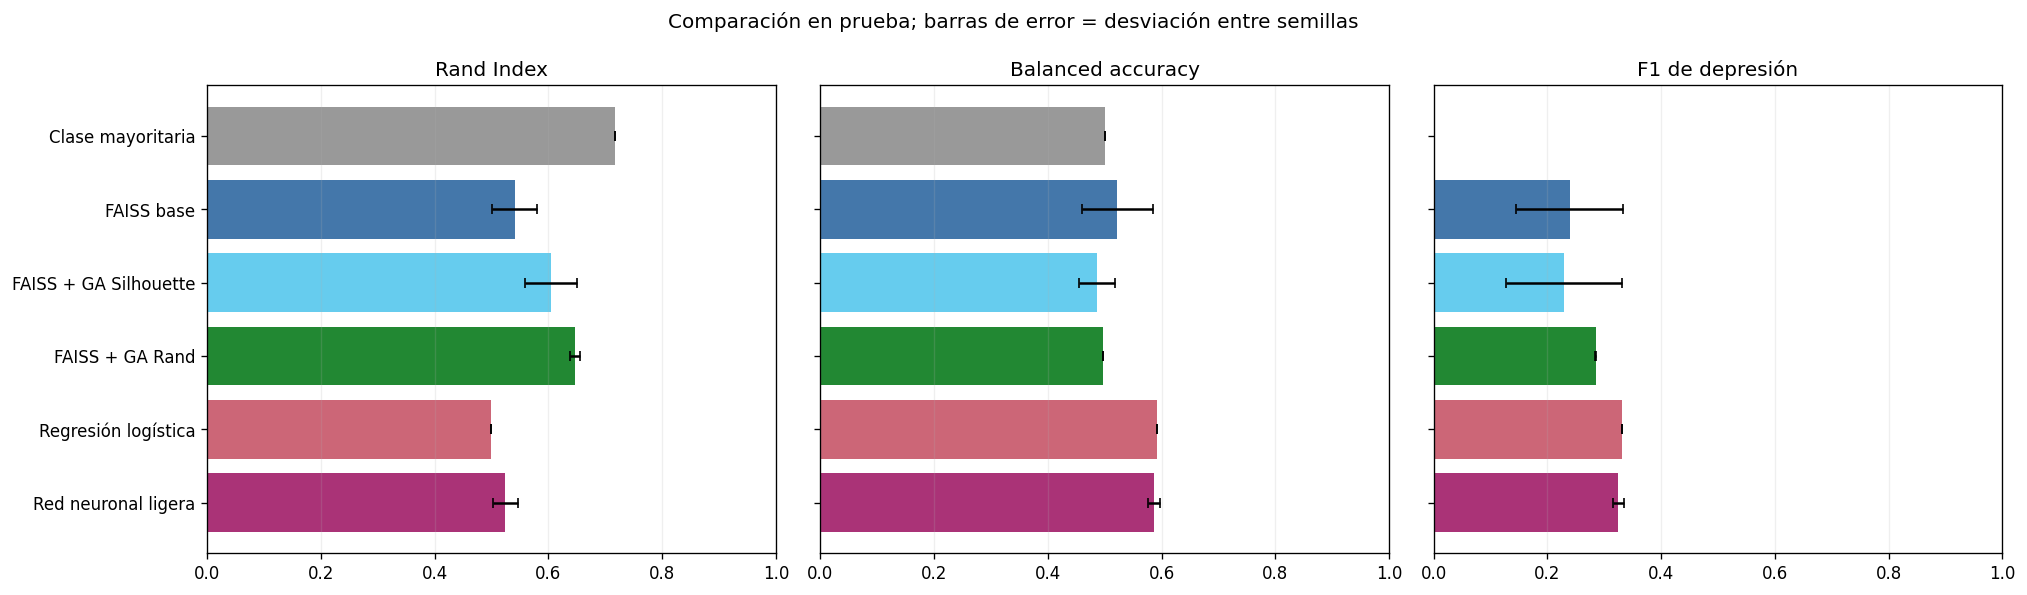

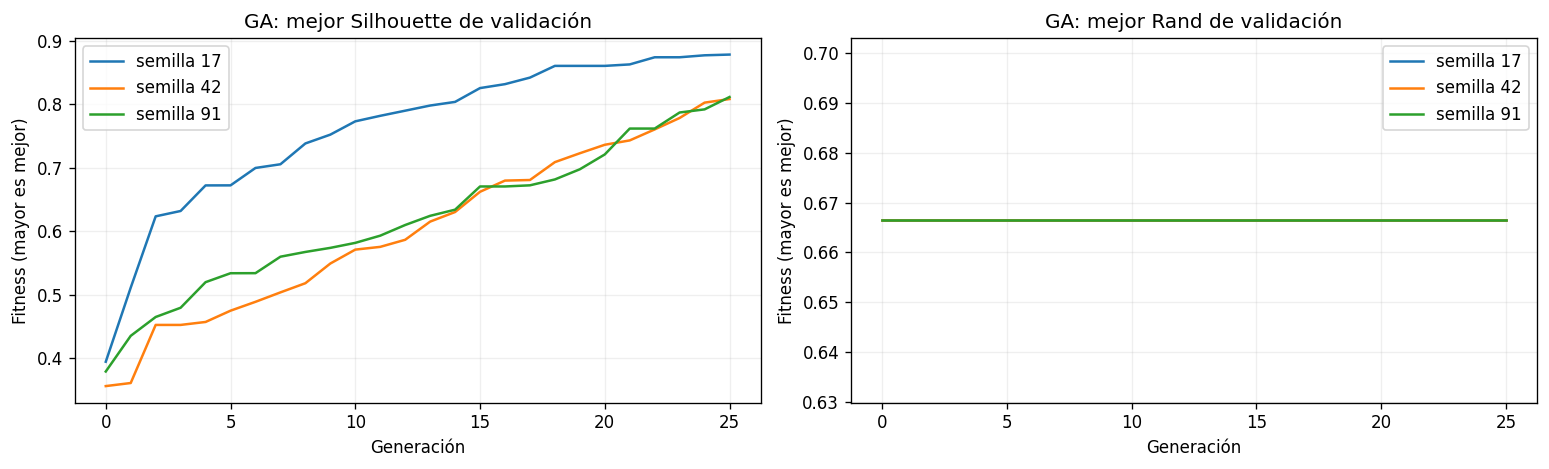

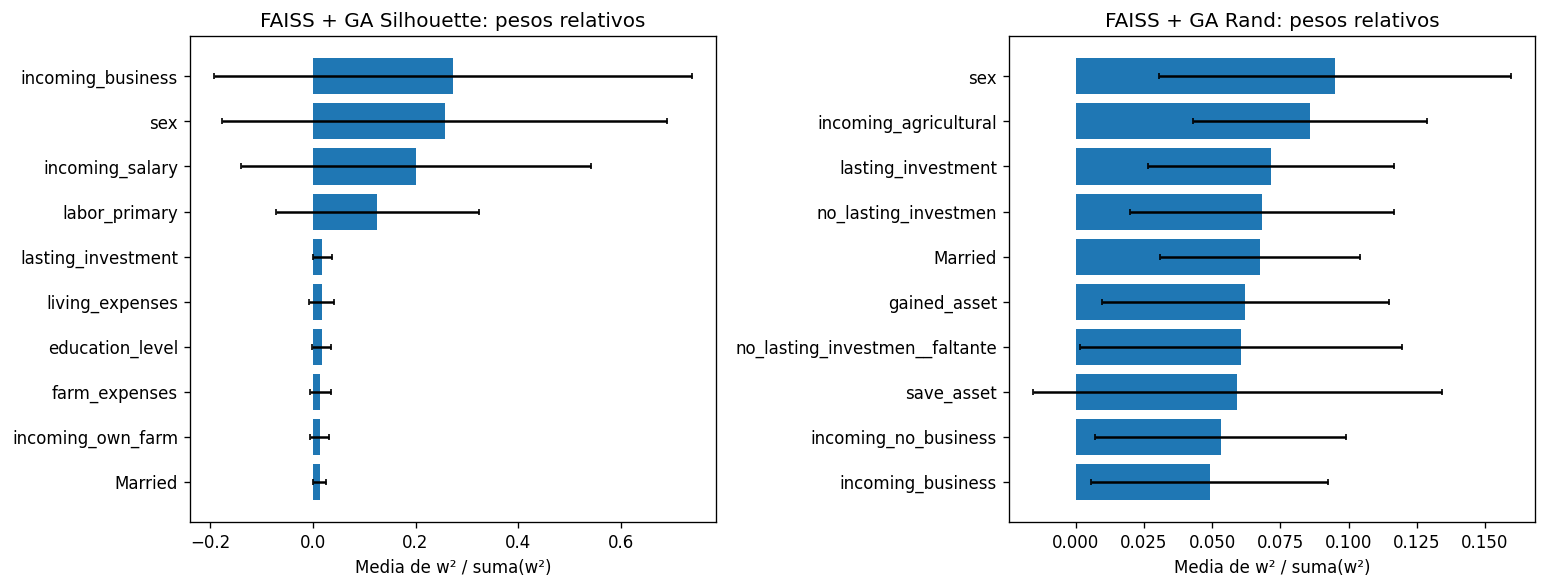

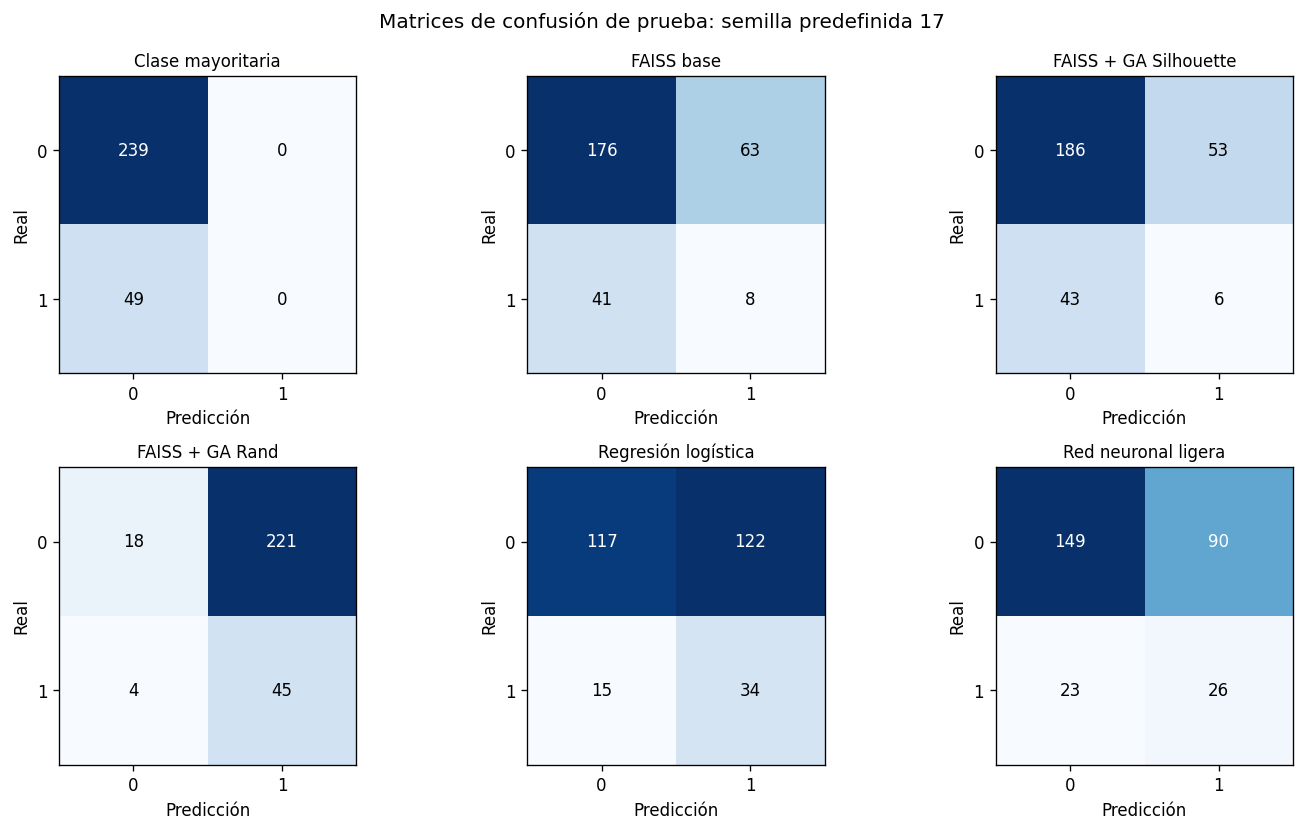

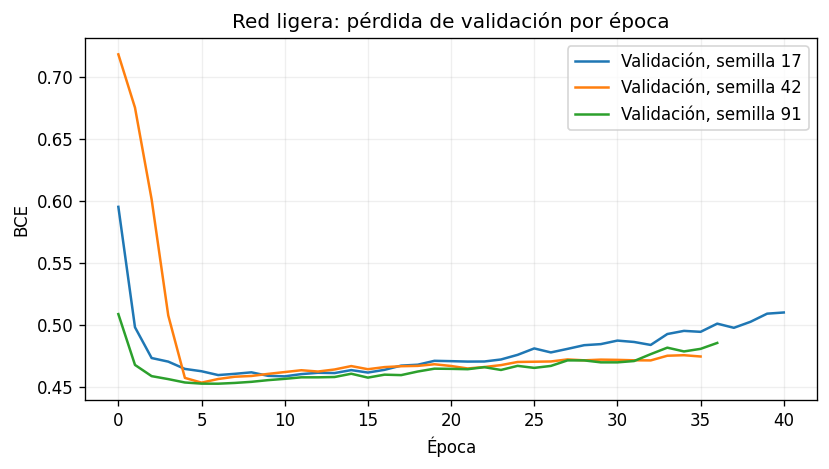

In [10]:
fig,axs=plt.subplots(1,3,figsize=(17,5))
for ax,metric,title in zip(axs,["rand_index","balanced_accuracy","f1"],
                           ["Rand Index","Balanced accuracy","F1 de depresión"]):
    means=[summary[m][metric][0] for m in METHODS]
    errors=[summary[m][metric][1] for m in METHODS]
    ax.barh(np.arange(len(METHODS)),means,xerr=errors,color=["#999999","#4477aa","#66ccee","#228833","#cc6677","#aa3377"],capsize=3)
    ax.set_yticks(np.arange(len(METHODS)),METHODS if ax is axs[0] else [""]*len(METHODS))
    ax.set_xlim(0,1); ax.set_title(title); ax.invert_yaxis(); ax.grid(axis="x",alpha=.2)
fig.suptitle("Comparación en prueba; barras de error = desviación entre semillas")
plt.tight_layout(); plt.show()

fig,axs=plt.subplots(1,2,figsize=(13,4))
for (method,seed),history in ga_histories.items():
    ax=axs[0 if "Silhouette" in method else 1]
    ax.plot(history[:,0],-history[:,1],label=f"semilla {seed}")
for ax,title in zip(axs,["GA: mejor Silhouette de validación","GA: mejor Rand de validación"]):
    ax.set_title(title); ax.set_xlabel("Generación"); ax.set_ylabel("Fitness (mayor es mejor)")
    ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

fig,axs=plt.subplots(1,2,figsize=(13,5))
for ax,method in zip(axs,["FAISS + GA Silhouette","FAISS + GA Rand"]):
    ws=np.array([a["weights"] for a in artifacts if a["method"]==method])
    shares=ws**2/np.sum(ws**2,axis=1,keepdims=True)
    mean=shares.mean(0); ids=np.argsort(mean)[-10:]
    ax.barh(np.array(feature_names)[ids],mean[ids],xerr=shares.std(0,ddof=1)[ids],capsize=2)
    ax.set_title(method+": pesos relativos"); ax.set_xlabel("Media de w² / suma(w²)")
plt.tight_layout(); plt.show()

# Matrices por una semilla fijada de antemano, sin elegir la mejor sobre prueba.
fig,axs=plt.subplots(2,3,figsize=(12,7))
for ax,method in zip(axs.ravel(),METHODS):
    pred=predictions[(method,SEEDS[0])]["pred"]
    matrix=np.array([[np.sum((yte==i)&(pred==j)) for j in (0,1)] for i in (0,1)])
    ax.imshow(matrix,cmap="Blues")
    for i in (0,1):
        for j in (0,1):
            ax.text(j,i,str(matrix[i,j]),ha="center",va="center",
                    color="white" if matrix[i,j]>matrix.max()/2 else "black")
    ax.set_xticks([0,1]); ax.set_yticks([0,1]); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
    ax.set_title(method,fontsize=10)
fig.suptitle(f"Matrices de confusión de prueba: semilla predefinida {SEEDS[0]}")
plt.tight_layout(); plt.show()

fig,ax=plt.subplots(figsize=(7,4))
for seed,h in mlp_histories.items():
    ax.plot(h[:,1],label=f"Validación, semilla {seed}")
ax.set_title("Red ligera: pérdida de validación por época"); ax.set_xlabel("Época"); ax.set_ylabel("BCE")
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()


## 8. Interpretación automática y evaluación comparativa

La lectura principal debe separar **compacidad geométrica** de **coincidencia con depresión**. Un Silhouette alto puede representar separación por edad, patrimonio u otra variable, y no por la etiqueta. RI puede ser alto incluso para una partición inútil si domina una clase; por eso se compara con la clase mayoritaria, ARI, balanced accuracy y F1.

Las siguientes conclusiones se generan con los resultados reales de esta ejecución. No se supone que el GA o la red ganan. El ranking de prueba es descriptivo y no se reutiliza para ajustar configuraciones.


In [11]:
mean=lambda method,metric: summary[method][metric][0]
base="FAISS base"; ga_s="FAISS + GA Silhouette"; ga_r="FAISS + GA Rand"
best_pred=max(METHODS,key=lambda m:mean(m,"balanced_accuracy"))
best_ri=max(METHODS,key=lambda m:mean(m,"rand_index"))
delta_ri=mean(ga_r,"rand_index")-mean(base,"rand_index")
delta_s=mean(ga_s,"silhouette_common")-mean(base,"silhouette_common")
text=f"""**Lectura de esta ejecución**

- Mayor balanced accuracy media en prueba: **{best_pred}**, {mean(best_pred,'balanced_accuracy'):.3f}; F1 {mean(best_pred,'f1'):.3f}, recall {mean(best_pred,'recall'):.3f} y ROC-AUC {mean(best_pred,'roc_auc'):.3f}.
- Mayor Rand medio: **{best_ri}**, {mean(best_ri,'rand_index'):.3f}. La referencia mayoritaria alcanza RI {mean('Clase mayoritaria','rand_index'):.3f}, ARI {mean('Clase mayoritaria','adjusted_rand'):.3f} y balanced accuracy {mean('Clase mayoritaria','balanced_accuracy'):.3f}.
- GA-Rand frente a FAISS base: cambio de RI en prueba **{delta_ri:+.3f}**. {'Mejora' if delta_ri>0 else 'No mejora'} el promedio observado; su selección se hizo en validación, no en prueba.
- GA-Silhouette frente a FAISS base: cambio de Silhouette en espacio común **{delta_s:+.3f}**. Su Silhouette propio es {mean(ga_s,'silhouette_own'):.3f}; usa una geometría distinta y no demuestra por sí solo mejor detección de depresión.
- Logística: BA {mean('Regresión logística','balanced_accuracy'):.3f}, F1 {mean('Regresión logística','f1'):.3f}. Red ligera: BA {mean('Red neuronal ligera','balanced_accuracy'):.3f}, F1 {mean('Red neuronal ligera','f1'):.3f}. La complejidad adicional de la red debe justificarse con mejoras consistentes.

**Límites:** una única partición no establece superioridad estadística. Las tres semillas comparten las mismas personas. El GA puede sobreajustar validación, y la ponderación no implica causalidad ni importancia clínica. Una métrica diagonal tampoco modela interacciones como una red. Para un estudio más sólido: validación anidada, varias particiones y separación por municipio si el objetivo es generalizar a lugares nuevos. Este experimento describe la etiqueta del dataset; no es una herramienta diagnóstica validada.
"""
display(Markdown(text))
(OUTPUT_DIR/"conclusiones.md").write_text(text,encoding="utf-8")


**Lectura de esta ejecución**

- Mayor balanced accuracy media en prueba: **Regresión logística**, 0.592; F1 0.332, recall 0.694 y ROC-AUC 0.623.
- Mayor Rand medio: **Clase mayoritaria**, 0.717. La referencia mayoritaria alcanza RI 0.717, ARI 0.000 y balanced accuracy 0.500.
- GA-Rand frente a FAISS base: cambio de RI en prueba **+0.106**. Mejora el promedio observado; su selección se hizo en validación, no en prueba.
- GA-Silhouette frente a FAISS base: cambio de Silhouette en espacio común **+0.008**. Su Silhouette propio es 0.823; usa una geometría distinta y no demuestra por sí solo mejor detección de depresión.
- Logística: BA 0.592, F1 0.332. Red ligera: BA 0.586, F1 0.325. La complejidad adicional de la red debe justificarse con mejoras consistentes.

**Límites:** una única partición no establece superioridad estadística. Las tres semillas comparten las mismas personas. El GA puede sobreajustar validación, y la ponderación no implica causalidad ni importancia clínica. Una métrica diagonal tampoco modela interacciones como una red. Para un estudio más sólido: validación anidada, varias particiones y separación por municipio si el objetivo es generalizar a lugares nuevos. Este experimento describe la etiqueta del dataset; no es una herramienta diagnóstica validada.


## 9. Exportar resultados y trazabilidad

Se guardan resultados individuales y agregados, pesos firmados y contribuciones a la distancia, predicciones de prueba, historial del GA, configuración y conclusiones. Los tiempos son de entrenamiento/selección; no incluyen instalación ni métricas finales. En logística se repite el tiempo de su único ajuste para mantener filas comparables. El ZIP se puede descargar desde el panel de archivos de Colab o activando `DOWNLOAD_ZIP`.


In [12]:
def write_rows(path, rows):
    fields=list(dict.fromkeys(k for row in rows for k in row))
    with open(path,"w",newline="",encoding="utf-8") as f:
        writer=csv.DictWriter(f,fieldnames=fields); writer.writeheader(); writer.writerows(rows)
write_rows(OUTPUT_DIR/"metricas_prueba.csv",results)
write_rows(OUTPUT_DIR/"seleccion_validacion.csv",training_log)
aggregate=[]
for method in METHODS:
    r={"method":method}
    for metric in METRICS:
        r[metric+"_mean"],r[metric+"_std"]=summary[method][metric]
    aggregate.append(r)
write_rows(OUTPUT_DIR/"resumen_comparativo.csv",aggregate)
weights_rows=[]
for art in artifacts:
    if art["kind"]=="cluster":
        w=art["weights"]
        for name,value,share in zip(feature_names,w,w**2/np.sum(w**2)):
            weights_rows.append(dict(method=art["method"],seed=art["seed"],feature=name,
                                     weight=float(value),distance_share=float(share)))
write_rows(OUTPUT_DIR/"pesos.csv",weights_rows)
pred_rows=[]
for (method,seed),data in predictions.items():
    for row_id,actual,pred,score in zip(idx_test,yte,data["pred"],data["score"]):
        pred_rows.append(dict(method=method,seed=seed,csv_row=int(row_id)+2,
                              actual=int(actual),predicted=int(pred),score=float(score)))
write_rows(OUTPUT_DIR/"predicciones_prueba.csv",pred_rows)
write_rows(OUTPUT_DIR/"historial_ga.csv",[
    dict(method=m,seed=s,generation=int(g),best_cost=float(b),mean_valid_cost=float(a))
    for (m,s),h in ga_histories.items() for g,b,a in h])
config=dict(split_seed=SEED_SPLIT,algorithm_seeds=SEEDS,ga_population=GA_POP,
            ga_generations=GA_GENERATIONS,ga_keep=GA_KEEP,ga_mutation=GA_MUTATION,
            ga_sigma=GA_SIGMA,faiss_k=K,faiss_niter=30,faiss_nredo=3,
            csv_sha256=hashlib.sha256(csv_bytes).hexdigest(),features=feature_names,
            train_indices=idx_train.tolist(),val_indices=idx_val.tolist(),test_indices=idx_test.tolist(),
            preprocessing_median=prep.median.tolist(),preprocessing_mean=prep.mean.tolist(),
            preprocessing_std=prep.std.tolist(),missing_indicator_columns=prep.missing_cols.tolist(),
            numpy=np.__version__,torch=torch.__version__,faiss=getattr(faiss,"__version__","unknown"))
(OUTPUT_DIR/"configuracion.json").write_text(json.dumps(config,indent=2),encoding="utf-8")
import shutil
zip_path=shutil.make_archive(str(OUTPUT_DIR),"zip",OUTPUT_DIR)
print("Resultados exportados:",zip_path)
DOWNLOAD_ZIP=False
if DOWNLOAD_ZIP:
    from google.colab import files
    files.download(zip_path)


Resultados exportados: /workspace/scratch/5238fc3cb714/resultados_depresion.zip


## Referencias y decisiones reproducibles

- [Dataset en Kaggle](https://www.kaggle.com/datasets/diegobabativa/depression). La fuente efectiva es el CSV adjunto integrado y verificado por su hash.
- Código base: `genetic.py` adjunto. Las funciones del GA mantienen nombres/etapas reconocibles, adaptadas a codificación real.
- [FAISS: k-means clustering](https://github.com/facebookresearch/faiss/wiki/Faiss-building-blocks:-clustering,-PCA,-quantization): entrenamiento y asignación al centro más próximo mediante búsqueda del índice.
- [Definiciones de evaluación de clustering](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation): Silhouette, Rand y Rand ajustado. Solo se consulta la documentación; no se importa scikit-learn.
- [PyTorch: BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html).

Para repetir el análisis, conserva el CSV/hash, las versiones impresas, la configuración y las semillas. Las pequeñas diferencias numéricas entre versiones de FAISS/PyTorch o equipos pueden producir cambios en centroides o mínimos locales. CPU y un hilo reducen esa variación.
